# Section 4: Toxic comment classification: Bi-LSTM with GloVe

Trains a bidirectional LSTM on the pooled toxicity data from `3_pooled_data.ipynb` (YouTube, Wikipedia, news and Dota chat comments with a binary `label`), tunes it with Bayesian search and k-fold cross-validation, and evaluates the best model on the pooled validation split and zero-shot on r/jobs comments.

Pipeline: load the pooled train / validation splits → tokenize (fitted on the training text) and pad → GloVe embedding matrix → Bayesian search (each candidate scored by k-fold CV on the training split) → evaluate the best model on the validation split → Reddit zero-shot test.

Run `3_pooled_data.ipynb` first: it creates `dataset/pooled/pooled_train.csv`, `pooled_val.csv` and `manifest.json`.

## 1. Setup
Imports, the shared project code in the `functions/` package (`preprocessing`, `embeddings`, `cv`, `tuning`), and a filter for a harmless Keras warning about masking.

In [57]:
from pathlib import Path
import subprocess
import sys
import os

repo = Path("/content/IS5126_grp6_final_project")

# 如果完整项目还没下载，就下载
if not repo.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/muffinMonday/IS5126_grp6_final_project.git",
            str(repo),
        ],
        check=True,
    )

# 检查项目代码是否存在
assert (repo / "functions" / "preprocessing.py").exists(), (
    f"项目文件不完整，请检查：{repo}"
)

# 让 Python 能导入 functions
sys.path.insert(0, str(repo))

# 保证 notebook 里的 ../dataset 等路径正确
os.chdir(repo / "notebook")

print("当前目录：", Path.cwd())
print("functions 文件夹已找到")

当前目录： /content/IS5126_grp6_final_project/notebook
functions 文件夹已找到


In [58]:
%pip install scikit-optimize

In [59]:
# Add the parent directory ('Project Template') to Python's search path
import sys
sys.path.append('..')

# project code: see functions/__init__.py for what each module contains
from functions.preprocessing import cleanup_text
from functions.embeddings import build_embedding_matrix, download_glove, glove_filename
from functions.cv import kfold_wrapper
from functions.tuning import bayes_search


import os
import re
import json
import hashlib
import string
import warnings
import numpy as np
import unicodedata
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import StratifiedKFold
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Embedding
from tensorflow.keras.models import Sequential
from sklearn.model_selection import train_test_split
from skopt.space import Categorical, Integer, Real
import matplotlib.pyplot as plt

# the nightly Keras build wrongly warns that LSTM / Bidirectional destroy the mask (masking works)
warnings.filterwarnings('ignore', message='.*was passed an input with a mask attached.*')

## 2. Load the pooled data
Reads the fixed train / validation splits written by `3_pooled_data.ipynb` to `../dataset/pooled/`. Each row has `orig_id`, `source`, `text_raw`, `text` (lower-cased and cleaned) and `label` (1 = toxic). The splits are stratified by source and label, so training and validation have the same toxic share within every source. The files are checked against `manifest.json`, so the notebook stops if they were edited or regenerated differently. The table shows the number of rows and the toxic share per source and split.

In [60]:
pooled_dir = '../dataset/pooled'
train_path = os.path.join(pooled_dir, 'pooled_train.csv')
val_path = os.path.join(pooled_dir, 'pooled_val.csv')
manifest_path = os.path.join(pooled_dir, 'manifest.json')
for path in (train_path, val_path, manifest_path):
    if not os.path.exists(path):
        raise FileNotFoundError(f'{path} not found. Run notebook/3_pooled_data.ipynb first to create the pooled splits.')

def read_pooled(path):
    # orig_id must stay a string and empty strings must not become NaN
    return pd.read_csv(path, dtype={'orig_id': str}, keep_default_na=False)

train_df, val_df = read_pooled(train_path), read_pooled(val_path)

# the splits must be the ones recorded in the manifest (data, mapping or cleaning may have changed since)
with open(manifest_path, encoding='utf-8') as f:
    manifest = json.load(f)
for name, frame in [('train', train_df), ('val', val_df)]:
    digest = hashlib.sha256(frame.to_csv(index=False, lineterminator='\n').encode()).hexdigest()
    if digest != manifest['split_sha256'][name]:
        raise ValueError(f'pooled_{name}.csv does not match manifest.json: regenerate the splits with notebook 3.')

summary = (pd.concat([train_df.assign(split='train'), val_df.assign(split='val')])
           .groupby(['source', 'split'])['label'].agg(rows='size', toxic_share='mean').unstack('split'))
summary.round(3)

rows       toxic_share       
split     train   val       train    val
source                                  
dota       2429   608       0.453  0.452
news       7968  1992       0.080  0.080
wikipedia  7997  1999       0.102  0.102
youtube     793   198       0.462  0.460

## 3. Check the cleaned text
The pooled `text` column was already produced by `cleanup_text` in notebook 3 (lower-case, HTML and URL removal, contraction expansion, punctuation handling), so nothing is cleaned again here. A spot check re-cleans a sample of the raw text and stops if the result differs from the stored text, which happens when `cleanup_text` has changed since the splits were made. Prediction applies the same function to new comments, so the training and prediction inputs have to match.

In [61]:
commentsCol = 'text'   # already lower-cased and cleaned in notebook 3
labelCol = 'label'     # 1 = toxic, 0 = non-toxic

# spot check: the stored text must equal what the current cleanup_text gives for the raw text
check = train_df.sample(min(1000, len(train_df)), random_state=0)
stale = (check['text_raw'].str.lower().apply(cleanup_text) != check[commentsCol]).sum()
if stale:
    raise ValueError(f'{stale} of {len(check)} sampled texts differ from the current cleanup_text: re-run notebook 3.')
print(f'Cleaning check passed on {len(check)} sampled training comments.')

Cleaning check passed on 1000 sampled training comments.


## 4. Explore the data
Rows and toxic share per source, and the distribution of comment lengths (in words) per source, for the training split. The sources differ a lot: Dota chat messages are only a few words long, while news and Wikipedia comments are much longer (notebook 3 has the exact figures). This informs the padding length (`max_length`) chosen in the next step.

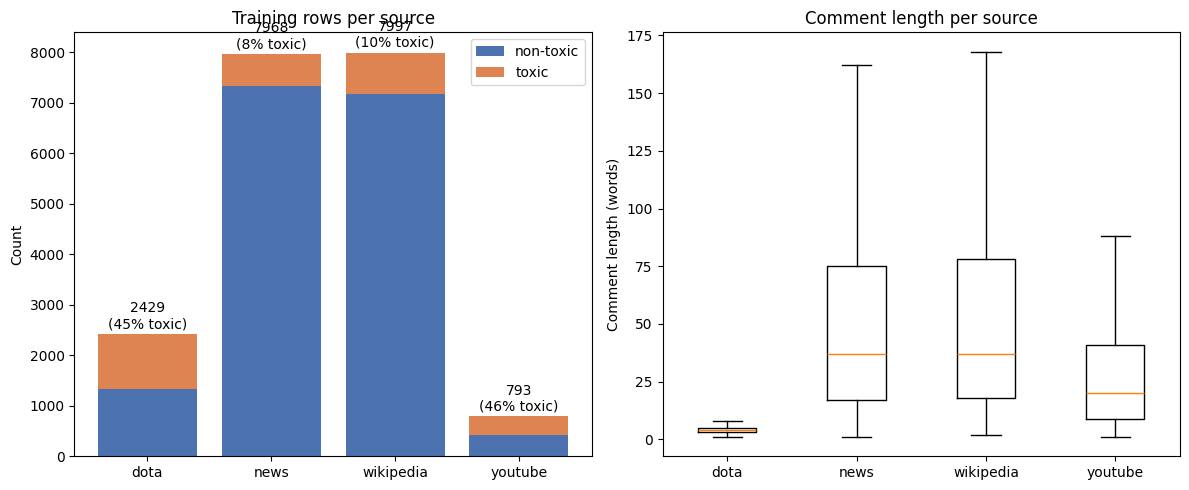

In [62]:
counts = train_df.groupby('source')[labelCol].agg(rows='size', toxic='sum')
lengths = train_df[commentsCol].str.split().str.len()

fig, ax = plt.subplots(figsize=(12, 5), nrows=1, ncols=2)

# rows per source, split into non-toxic and toxic
ax[0].bar(counts.index, counts['rows'] - counts['toxic'], color='#4C72B0', label='non-toxic')
ax[0].bar(counts.index, counts['toxic'], bottom=counts['rows'] - counts['toxic'], color='#DD8452', label='toxic')
for i, (rows, toxic) in enumerate(zip(counts['rows'], counts['toxic'])):
    ax[0].text(i, rows + 50, f'{rows}\n({toxic / rows:.0%} toxic)', ha='center', va='bottom', fontsize=10)
ax[0].set_ylabel('Count')
ax[0].set_title('Training rows per source')
ax[0].legend()

# comment length in words per source (outliers hidden)
ax[1].boxplot([lengths[train_df['source'] == s] for s in counts.index], tick_labels=counts.index, showfliers=False)
ax[1].set_ylabel('Comment length (words)')
ax[1].set_title('Comment length per source')
plt.tight_layout()
plt.show()

## 5. Tokenize and pad
Sets the vocabulary size, the padded length and the embedding dimension, which are reused by the model and the inference function. The tokenizer maps each word to an integer id and is **fitted on the training texts only**, so the validation comments don't influence the vocabulary (the pooled splits exist before this step). Sequences are padded or truncated at the end to a fixed `max_length`, with 0 reserved for padding. The printed shares show how many training comments per source are longer than `max_length` and are therefore truncated.

`embed_dim` must match the GloVe file loaded next.

In [63]:
# Initialize the tokenizer
vocab_size = 10000
max_length = 80
embed_dim = 100  # must match the GloVe file (50, 100, 200 or 300)

tokenizer = Tokenizer(num_words=vocab_size, oov_token='<OOV>')

# Fit the tokenizer on the training texts only (this learns the vocabulary)
tokenizer.fit_on_texts(train_df[commentsCol])

# Convert texts to sequences of integers
train_sequences = tokenizer.texts_to_sequences(train_df[commentsCol])
val_sequences = tokenizer.texts_to_sequences(val_df[commentsCol])

# Example of what this looks like
print('Original:', train_df[commentsCol].iloc[0])
print('\nTokenized sequence:', train_sequences[0])

# Pad sequences
X_train = pad_sequences(train_sequences, maxlen=max_length, padding='post', truncating='post')
X_val = pad_sequences(val_sequences, maxlen=max_length, padding='post', truncating='post')
y_train = train_df[labelCol]
y_val = val_df[labelCol]

print('\nPadded shapes:', X_train.shape, X_val.shape)

# share of training comments cut off at max_length, per source
truncated = train_df[commentsCol].str.split().str.len().gt(max_length)
print('\nTruncated at max_length:')
print(truncated.groupby(train_df['source']).mean().round(3).to_string())

Original: wtf u want from me

Tokenized sequence: [2134, 186, 104, 31, 52]

Padded shapes: (19187, 80) (4797, 80)

Truncated at max_length:
source
dota         0.000
news         0.228
wikipedia    0.240
youtube      0.102


### Handle empty token sequences
Some nonempty comments, such as `! ! ! !`, become empty after tokenizer filtering. With `mask_zero=True`, an all-zero row can fail the GPU cuDNN LSTM mask check. Replace only its first padding value with the existing OOV ID. Keep all rows and labels, retain right-padding and apply this same rule during prediction. This does not change the tokenizer vocabulary or the pooled CSVs.


In [64]:
# [Modified] Use the same empty-sequence policy for training and inference.
def fix_empty_sequences(X, text_tokenizer=None):
    text_tokenizer = tokenizer if text_tokenizer is None else text_tokenizer
    X = np.asarray(X).copy()
    if X.ndim != 2 or X.shape[1] == 0:
        raise ValueError('Expected a two-dimensional padded array with positive width.')

    oov_id = text_tokenizer.word_index.get(text_tokenizer.oov_token)
    limit = text_tokenizer.num_words
    if oov_id is None or oov_id <= 0 or (limit is not None and oov_id >= limit):
        raise ValueError('The tokenizer must contain a usable OOV token.')

    empty = (X == 0).all(axis=1)
    X[empty, 0] = oov_id
    return X, int(empty.sum())

X_train, n_train_fixed = fix_empty_sequences(X_train)
X_val, n_val_fixed = fix_empty_sequences(X_val)
print('Empty training sequences repaired:', n_train_fixed)
print('Empty validation sequences repaired:', n_val_fixed)
assert (X_train != 0).any(axis=1).all()
assert (X_val != 0).any(axis=1).all()


Empty training sequences repaired: 1
Empty validation sequences repaired: 0


## 6. Load GloVe embeddings
Builds the embedding matrix that initialises the model's embedding layer: row *i* holds the pre-trained GloVe vector of the word with id *i*. It uses the local copy in `../glove` and downloads the file there first if it is missing. Words GloVe doesn't know get small random vectors. The printed coverage is the share of distinct vocabulary words found in GloVe.

In [65]:
# Load pre-trained GloVe vectors, preferring the local copy in ../glove
glove_dir = '../glove'
glove_path = os.path.join(glove_dir, glove_filename(embed_dim))

try:
    embedding_matrix, glove_coverage = build_embedding_matrix(glove_path, tokenizer.word_index, vocab_size)
except FileNotFoundError:
    print(f'{glove_path} not found.')
    download_glove(embed_dim, glove_dir)
    embedding_matrix, glove_coverage = build_embedding_matrix(glove_path, tokenizer.word_index, vocab_size)

print('Embedding matrix shape:', embedding_matrix.shape)
print(f'Vocabulary found in GloVe: {glove_coverage:.1%}')

Embedding matrix shape: (10000, 100)
Vocabulary found in GloVe: 98.5%


## 7. Reference model
A fixed example of the architecture: GloVe-initialised embedding (frozen, with padding masked) → Bi-LSTM → sigmoid output, compiled with several metrics. The search below rebuilds the model itself through `build_model`, so this cell is not needed for the search or for evaluating the best model. It shows the architecture and its summary.

In [66]:
# 1. Define parameters based on tokenization step
v_size = (
    vocab_size  # Max number of unique words your tokenizer tracked (e.g., top 5,000)
)
embedding_dim = (
    embed_dim  # The number of dimensions (coordinates) for each word vector
)
m_length = (
    max_length  # The fixed length of your padded sequences (e.g., 50 words per comment)
)

# 2. Build the Model Architecture
model = Sequential([
    # The Embedding Layer: integer-to-vector lookup, initialised with GloVe and frozen;
    # mask_zero makes the LSTM skip the padding (index 0)
    Embedding(
        input_dim=v_size,
        output_dim=embedding_dim,
        embeddings_initializer=tf.keras.initializers.Constant(embedding_matrix),
        trainable=False,
        mask_zero=True,
    ),
    # The Bi-LSTM Layer: reads the sequence forwards and backwards, then concatenates both outputs
    Bidirectional(LSTM(8, dropout=0.2, recurrent_dropout=0.2)),
    # The Output Layer: Binary classification (toxic = 1, not toxic = 0)
    Dense(1, activation='sigmoid'),
])

# 3. Compile the model
model.compile(
loss='binary_crossentropy',
    optimizer='adam',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),  # Recall = True Positive Rate
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.F1Score(name='f1_score', threshold=0.5)
    ]
)

# Print the model summary to see the shapes match up
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 8. Train / validation data
The training and validation sets come from notebook 3 (80/20, stratified by source and label), so nothing is split here. The validation split is never used for training or tuning. K-fold cross-validation runs inside the training split only, and its folds are stratified by label, not by source. The commented-out block is a quick manual test of `kfold_wrapper` on the reference model.

In [67]:
# the pooled splits come from notebook 3 (stratified by source and label); nothing is split here
print(f'Training: {X_train.shape[0]:,} comments | validation: {X_val.shape[0]:,} comments')
print(f'Toxic share: training {y_train.mean():.3f} | validation {y_val.mean():.3f}')

# test the k-fold cross-validation wrapper function
'''
print("Evaluating model...")
evaluated_object = kfold_wrapper(model, X_train, y_train, X_val, y_val, n_splits = 5, epochs = 5, batch_size = 16)
print(evaluated_object.avg_train_metrics)
print(evaluated_object.validation_metrics)
'''

Training: 19,187 comments | validation: 4,797 comments
Toxic share: training 0.152 | validation 0.152


'\nprint("Evaluating model...")\nevaluated_object = kfold_wrapper(model, X_train, y_train, X_val, y_val, n_splits = 5, epochs = 5, batch_size = 16)\nprint(evaluated_object.avg_train_metrics)\nprint(evaluated_object.validation_metrics)\n'

## 9. Hyperparameter search
Defines how a model is built from a set of hyperparameters (`build_model`) and the search space (embedding trainable or frozen, LSTM size, dropout, learning rate). The Bayesian search scores each candidate with stratified k-fold CV on the pooled training split and maximises the average validation PR-AUC.

**Choosing the model.** The top trials are usually within noise of each other, so the search selects, among the trials whose mean PR-AUC is within one fold standard deviation of the best, the one with the lowest standard deviation across folds (`selection='stable'`). It returns that trial's `kfold_wrapper`, whose final model is trained on the full training split and scored on the pooled validation split.

**Choosing the threshold.** The model's cutoff is chosen on the out-of-fold predictions of the training split: the highest-recall cutoff whose false positive rate (the share of non-toxic comments flagged) stays at or below `MAX_FPR`. The cap reflects how many false alarms moderators can review. A recall-weighted score such as F2 was tried first on the YouTube data, but it ran to the lowest cutoff and flagged most comments. The tuned value becomes the model's `threshold`, so the confusion matrix, precision–recall marker, error table, `toxicity_check` and the Reddit section below all use it. The tuning needs no re-training, so it also runs on a loaded result and you can change `MAX_FPR` without re-running the search. The hold-out numbers at the default 0.5 cutoff are printed too, for comparison.

**What the validation scores mean.** The pooled validation split contains comments from the same four sources as training, so its scores are in-domain and optimistic about r/jobs. Section 14 is the cross-domain test.

**Runtime.** The training split has about 19,000 comments instead of the 800 of the earlier YouTube-only setup, so every fit takes much longer, and the search fits about 180 models. To use the CPU better, `kfold_kwargs` has `'n_jobs': -1`: the 5 folds and the final model of each candidate are trained in separate processes at the same time. Each process needs its own memory, so use a smaller number if memory is short, or `1` to train one model after another. The results do not depend on `n_jobs`.

Results are saved to `../models/bayes_search_pooled`. If a saved result exists there, you are asked whether to load it or re-run the search. Choose to re-run after changing the data, preprocessing or search space, because a loaded result is not checked against them. The YouTube-only result in `../models/bayes_search` is not used.

In [68]:
def build_model(trainable, lstm_units, dropout, lr):
    m = Sequential([
        Embedding(
            input_dim=vocab_size,
            output_dim=embed_dim,
            embeddings_initializer=tf.keras.initializers.Constant(embedding_matrix),
            trainable=trainable,
            mask_zero=True,  # LSTM skips the padding (index 0)
        ),
        Bidirectional(LSTM(lstm_units, dropout=dropout)),
        Dense(1, activation='sigmoid'),
    ])
    m.compile(
        loss='binary_crossentropy',
        optimizer=tf.keras.optimizers.Adam(lr),
        metrics=[
            'accuracy',
            tf.keras.metrics.F1Score(name='f1_score', threshold=0.5),
            tf.keras.metrics.AUC(curve='PR', name='pr_auc'),
        ],
    )
    return m

search_space = {
    'trainable': Categorical([True, False]),  # fine-tune GloVe or keep it frozen
    'lstm_units': Integer(8, 128, prior='log-uniform'),
    'dropout': Real(0.0, 0.5),
    'lr': Real(3e-4, 1e-2, prior='log-uniform'),
    # 'epochs': Integer(10, 60),  # enable after the 5-epoch baseline, and drop epochs from kfold_kwargs
}

# Decision threshold: the highest-recall cutoff whose false positive rate (share of non-toxic
# comments flagged) stays at or below this cap, measured on out-of-fold predictions.
# Tuning needs no re-training, so changing the cap does not require re-running the search.
MAX_FPR = 0.35

# a previous run is saved here; the user chooses whether to load it or re-run the search
# (separate from the YouTube-only search in ../models/bayes_search, which used different data)
save_dir = 'save_dir = "../models/bayes_search_pooled_30trials_v1"'
rerun = True
if os.path.exists(os.path.join(save_dir, 'search_state.pkl')):
    answer = input('Found a previously optimised model. Load it [Y] or re-run the optimisation [N]? (default: Y) ').strip().lower()
    rerun = answer.lower().startswith('n')

if rerun:
    search = bayes_search(
        build_model, search_space, X_train, y_train, X_val, y_val,
        n_iter=30, n_initial_points=10, objective='pr_auc',
        # n_jobs=-1 trains the 5 folds and the final model in separate processes at the same time;
        # each process needs its own memory (watch it), so use a smaller number if memory is short,
        # or 1 to train one model after another
        kfold_kwargs={'n_splits': 5, 'epochs': 5, 'batch_size': 64, 'n_jobs': -1},
        selection='stable',  # among near-ties on mean PR-AUC, take the lowest std across folds
    )
    best_kf = search.fit()
else:
    search = bayes_search.load(save_dir)
    best_kf = search.best_kfold
    print(f'Loaded from {save_dir}')

# the validation set is not used to choose the threshold
if getattr(best_kf, 'oof_proba', None) is not None:
    tuning = best_kf.tune_threshold(max_fpr=MAX_FPR)
else:
    tuning = None
    print('No out-of-fold predictions in this saved result: re-run the search to tune the threshold.')

if rerun:
    search.save(save_dir)
    print(f'Saved to {save_dir}')

print('Selected trial:', getattr(search, 'best_trial', None), '| params:', search.best_params)
print('Hold-out @ threshold 0.5:  ', {k: round(v, 4) for k, v in best_kf.validation_metrics.items()})
if tuning is not None:
    print(f"Tuned threshold: {tuning['threshold']:.3f} ({tuning['rule']}); "
          f"out-of-fold recall {tuning['oof_recall']:.2f}, precision {tuning['oof_precision']:.2f}, FPR {tuning['oof_fpr']:.2f}")
    print('Hold-out @ tuned threshold:', {k: round(v, 4) for k, v in best_kf.tuned_validation_metrics.items()})
search.results.sort_values('avg_val_pr_auc', ascending=False).head()

Found a previously optimised model. Load it [Y] or re-run the optimisation [N]? (default: Y) y


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 20 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Loaded from save_dir = "../models/bayes_search_pooled_30trials_v1"
Selected trial: 26 | params: {'trainable': True, 'lstm_units': 9, 'dropout': 0.4996643288646504, 'lr': 0.0017707490585465965}
Hold-out @ threshold 0.5:   {'loss': 0.2452, 'accuracy': 0.9252, 'precision': 0.8136, 'recall': 0.6584, 'macro_f1': 0.8422, 'pr_auc': np.float64(0.8081), 'roc_auc': np.float64(0.9222)}
Tuned threshold: 0.050 (max recall with out-of-fold FPR <= 0.35); out-of-fold recall 0.87, precision 0.49, FPR 0.16
Hold-out @ tuned threshold: {'loss': 0.2452, 'accuracy': 0.8478, 'precision': 0.4996, 'recall': 0.834, 'macro_f1': 0.7647, 'pr_auc': np.float64(0.8081), 'roc_auc': np.float64(0.9222)}


,param_trainable,param_lstm_units,param_dropout,param_lr,Embedding_0__trainable,Embedding_0__input_dim,Embedding_0__output_dim,Embedding_0__mask_zero,Bidirectional_1__trainable,Bidirectional_1__merge_mode,...,std_val_pr_auc,std_val_roc_auc,holdout_loss,holdout_accuracy,holdout_precision,holdout_recall,holdout_macro_f1,holdout_pr_auc,holdout_roc_auc,selected
trial,,,,,,,,,,,,,,,,,,,,,
30,True,128,0.500000,0.001086,True,10000,100,True,True,concat,...,0.020586,0.012206,0.222676,0.927872,0.810373,0.685871,0.850496,0.825844,0.933540,False
18,True,128,0.500000,0.001222,True,10000,100,True,True,concat,...,0.021870,0.013260,0.230440,0.926412,0.794671,0.695473,0.849431,0.822990,0.932396,False
29,True,128,0.500000,0.001057,True,10000,100,True,True,concat,...,0.021456,0.012872,0.223218,0.925995,0.788580,0.700960,0.849495,0.826577,0.933932,False
23,True,128,0.500000,0.000896,True,10000,100,True,True,concat,...,0.021380,0.012454,0.215235,0.926204,0.794349,0.694102,0.848913,0.828331,0.935340,False
17,True,128,0.368744,0.000981,True,10000,100,True,True,concat,...,0.021257,0.012665,0.230281,0.925370,0.785824,0.699588,0.848315,0.821305,0.932721,False


## 10. Search progress
Validation PR-AUC (mean ± standard deviation across the CV folds) for every round of the search. The dotted line marks the end of the random initial points. Use it to see whether the search is still improving and how large the fold-to-fold noise is relative to the differences between rounds.

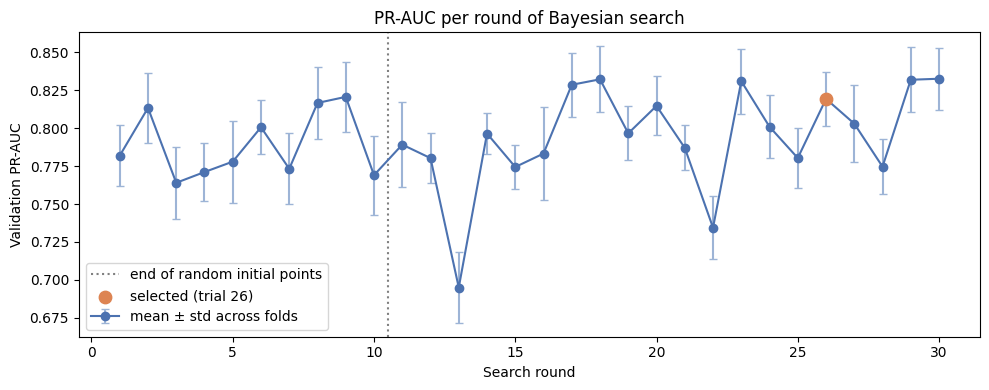

In [69]:
# mean +/- std (across the CV folds) of validation PR-AUC for each round of the search
res = search.results
mean, std = res['avg_val_pr_auc'], res['std_val_pr_auc']

fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(res.index, mean, yerr=std, fmt='o-', color='#4C72B0', ecolor='#9db4d6',
            capsize=3, label='mean ± std across folds')
ax.axvline(search.n_initial_points + 0.5, color='grey', linestyle=':', label='end of random initial points')
selected_trial = getattr(search, 'best_trial', None) or mean.idxmax()
ax.scatter([selected_trial], [mean[selected_trial]], color='#DD8452', zorder=3, s=80, label=f'selected (trial {selected_trial})')
ax.set_xlabel('Search round')
ax.set_ylabel('Validation PR-AUC')
ax.set_title('PR-AUC per round of Bayesian search')
ax.legend()
plt.tight_layout()
plt.show()

## 11. Evaluate the best model: confusion matrix
Predicts the held-out validation set with the best model and shows the confusion matrix at the model's threshold. It shows how many toxic comments are caught and how many clean ones are flagged.

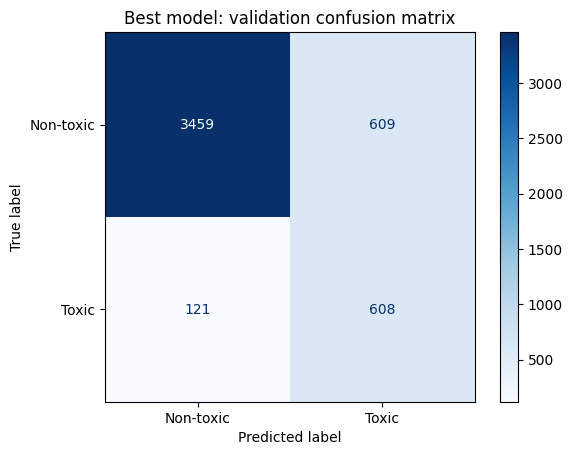

In [70]:
# confusion matrix of the best model on the validation set
from sklearn.metrics import ConfusionMatrixDisplay

proba = best_kf.final_model.predict(X_val, verbose=0).ravel()
pred = (proba >= best_kf.threshold).astype(int)

ConfusionMatrixDisplay.from_predictions(
    np.asarray(y_val).astype(int),
    pred,
    display_labels=['Non-toxic', 'Toxic'],
    cmap='Blues',
)
plt.title('Best model: validation confusion matrix')
plt.show()

### Precision–recall curve and PR-AUC
Plots precision (share of flagged comments that are toxic) against recall (share of toxic comments caught) as the cutoff moves from 1 to 0. PR-AUC (average precision) summarises how well the model ranks toxic above clean comments, independent of any threshold, and it is the metric the search maximises. The dashed line is the toxic share of the validation set, which is the PR-AUC of a model that ranks at random; 1.0 is perfect. The orange dot marks where the model's current threshold sits on the curve, so moving the threshold slides that point along the curve.

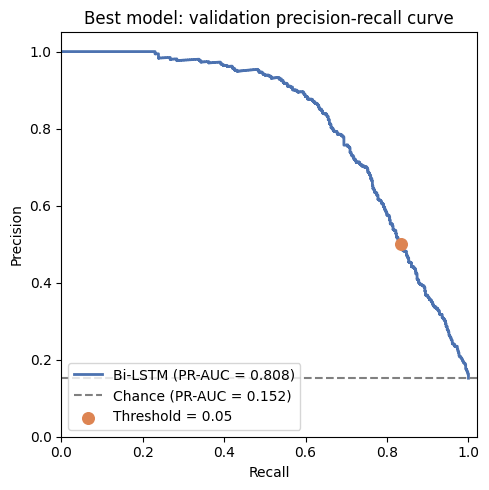

In [71]:
# Precision-recall curve of the best model on the validation set
from sklearn.metrics import precision_recall_curve, average_precision_score

proba = best_kf.final_model.predict(X_val, verbose=0).ravel()
actual = np.asarray(y_val).astype(int)

precision, recall, _ = precision_recall_curve(actual, proba)
pr_auc = average_precision_score(actual, proba)

# operating point at the model's threshold
pred = (proba >= best_kf.threshold).astype(int)
op_recall = ((pred == 1) & (actual == 1)).sum() / (actual == 1).sum()
op_precision = ((pred == 1) & (actual == 1)).sum() / max((pred == 1).sum(), 1)

fig, ax = plt.subplots(figsize=(5, 5))
ax.step(recall, precision, where='post', color='#4C72B0', linewidth=2, label=f'Bi-LSTM (PR-AUC = {pr_auc:.3f})')
ax.axhline(actual.mean(), color='grey', linestyle='--', label=f'Chance (PR-AUC = {actual.mean():.3f})')
ax.scatter([op_recall], [op_precision], color='#DD8452', zorder=3, s=70, label=f'Threshold = {best_kf.threshold:g}')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.05)
ax.set_title('Best model: validation precision-recall curve')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

### Cutoff trade-off (out-of-fold)
Shows what each cutoff does to recall, precision, false positive rate and the share of comments flagged, on the out-of-fold predictions of the training split. The row marked `tuned` is the cutoff chosen by the false positive cap. Lowering the cutoff catches more toxic comments but flags more clean ones, so use this table to judge whether the extra recall is worth the extra moderation work. The validation columns are a sanity check only. Training and validation have the same toxic share and the same four sources, so precision here is in-domain; on r/jobs, where the share of toxic comments is unknown and may be lower, precision would differ.

In [72]:
# Trade-off between catching toxic comments and false alarms at different cutoffs.
# oof_* : out-of-fold predictions on the training set, the basis for choosing the cutoff
# val_* : validation set, for checking only (it did not influence the cutoff)
# recall = share of toxic comments caught | precision = share of flagged comments that are toxic
# fpr = share of non-toxic comments flagged | flagged = share of all comments flagged
best_kf.threshold_table().round(2)

,oof_recall,oof_precision,oof_fpr,oof_flagged,val_recall,val_precision,val_fpr,val_flagged,note
threshold,,,,,,,,,
0.50,0.68,0.81,0.03,0.13,0.66,0.81,0.03,0.12,
0.40,0.71,0.77,0.04,0.14,0.69,0.78,0.03,0.13,
0.30,0.74,0.72,0.05,0.16,0.72,0.73,0.05,0.15,
0.25,0.75,0.69,0.06,0.16,0.73,0.71,0.05,0.16,
0.20,0.77,0.66,0.07,0.18,0.76,0.68,0.06,0.17,
0.15,0.79,0.62,0.09,0.19,0.77,0.64,0.08,0.18,
0.10,0.82,0.58,0.11,0.22,0.80,0.58,0.10,0.21,
0.05,0.87,0.49,0.16,0.27,0.83,0.50,0.15,0.25,tuned


## 12. Error analysis
Lists the mis-classified validation comments with the source, true label, predicted label, predicted probability, cleaned text and length in tokens, sorted by probability. Use it to look for patterns in the errors, such as differences between sources, truncated long comments, sarcasm or implicit toxicity, and noisy labels.

In [73]:
# mis-classified validation comments of the best model
proba = best_kf.final_model.predict(X_val, verbose=0).ravel()
pred = (proba >= best_kf.threshold).astype(int)
actual = np.asarray(y_val).astype(int)

errors = pd.DataFrame({
    'source': val_df['source'].values,
    'actual_label': actual,
    'predicted_label': pred,
    'predicted_probability': proba,
    'comment': val_df[commentsCol].values,  # cleaned text, as the model saw it
    'n_tokens': val_df[commentsCol].str.split().str.len().values,
}, index=val_df.index)

errors = errors[errors['actual_label'] != errors['predicted_label']]
errors['error_type'] = np.where(errors['actual_label'] == 1, 'missed toxic (FN)', 'false alarm (FP)')

print(errors['error_type'].value_counts().to_string())
print()
print(errors.groupby(['source', 'error_type']).size().unstack(fill_value=0).to_string())
pd.set_option('display.max_colwidth', 200)
errors.sort_values('predicted_probability')

error_type
false alarm (FP)     609
missed toxic (FN)    121

error_type  false alarm (FP)  missed toxic (FN)
source                                         
dota                     186                 13
news                     253                 53
wikipedia                118                 42
youtube                   52                 13


,source,actual_label,predicted_label,predicted_probability,comment,n_tokens,error_type
4322,wikipedia,1,0,0.000198,actually you are the cockroach that followed me to the notice board and repeatedly comes back to revert what i had written fyi 206 45 24 242 talk,28,missed toxic (FN)
2564,wikipedia,1,0,0.000237,sure i will sign my name on every post i make even though you refure to answer my compaint but now keep in mind that i will also sign it with a side note as a protest is this better for you mr rac...,81,missed toxic (FN)
536,wikipedia,1,0,0.000261,i am sorry the term was fappers meaning people who enjoy masturbating to said material flappers would suggest you are a bit dated and twenties ish maybe instead i should say that undue bias is giv...,79,missed toxic (FN)
3266,news,1,0,0.000295,wrong ! prior to the aca people at various risk did not get policies all the time without insurance companies knowing about it how silly you have obviously never heard of adverse selection is a fa...,119,missed toxic (FN)
1018,news,1,0,0.000310,reads first few paragraphs laden with assumptions and outright falsehoods wonders if the writer is just ignorant or has some other motive for authoring such a steaming pile quick google search rev...,66,missed toxic (FN)
...,...,...,...,...,...,...,...
670,dota,0,1,0.983474,wtf is that hero,4,false alarm (FP)
3568,wikipedia,0,1,0.985187,hey i like jews hey i like jews hey i like jews hey i like jews hey i like jews hey i like jews hey i like jews hey i like jews hey i like jews hey i like jews hey i like jews hey i like jews hey ...,1247,false alarm (FP)
381,dota,0,1,0.987201,i want to lose cuz i am noob,8,false alarm (FP)
2987,dota,0,1,0.987238,have manay space still noob,5,false alarm (FP)


## 13. Predict on new comments
`toxicity_check` applies the same pipeline to new text (clean → tokenize → pad → predict) with the best model and returns "Toxic" or "Non-toxic" using the model's threshold, or one you pass in. It depends on the tokenizer, `max_length` and `cleanup_text` above, so those must match what the model was trained with.

In [74]:
## pipeline to predict new data
def toxicity_check(new_comments, best_kf, threshold=None):
    # Use the wrapper's cutoff unless another one is given (e.g. a tuned threshold)
    threshold = best_kf.threshold if threshold is None else threshold

    # Clean the new comments
    cleaned_comments = [cleanup_text(comment.lower()) for comment in new_comments]

    # Convert to sequences
    sequences = tokenizer.texts_to_sequences(cleaned_comments)

    # Pad sequences
    padded_sequences = pad_sequences(sequences, maxlen=max_length, padding='post', truncating='post')

    # Predict with the trained model from the search
    probabilities = best_kf.final_model.predict(padded_sequences, verbose=0).ravel()

    return [{'label': 'Toxic' if p.round(4) >= threshold else 'Non-toxic', 'p': p} for p in probabilities]

### Testing
Runs `toxicity_check` on a sample comment as a quick sanity check.

In [75]:
toxicity_check(["wouldnt it be nice if you got hit by a bus?",
                "im so sorry to hear that you got hit by a bus",
                "I don’t mean to be insensitive with this question but isn’t it hard to be fired from a government job?",
                "you've got to be a genius to be fired from a government job",
                "you're as smart as a rock"], best_kf)

[{'label': 'Non-toxic', 'p': np.float32(0.014037245)},
 {'label': 'Non-toxic', 'p': np.float32(0.023964014)},
 {'label': 'Non-toxic', 'p': np.float32(0.007900374)},
 {'label': 'Toxic', 'p': np.float32(0.06957965)},
 {'label': 'Toxic', 'p': np.float32(0.17044288)}]

## 14. Reddit zero-shot validation
Evaluate the selected Bi-LSTM on the shared 100-comment r/jobs sample: **50 non-toxic (`0`) and 50 toxic (`1`) AI preliminary labels**. These are toxicity labels, not sentiment. The current file is pending human review, so its scores measure **agreement with AI annotations**, not accuracy against human-reviewed ground truth.

Run the setup, training-tokenizer and best-model sections above first (or load the matching saved search there). Reuse `best_kf.final_model`, the same `tokenizer`, `max_length`, and the existing `best_kf.threshold`. The threshold was selected before seeing Reddit; this section does not train, fit a tokenizer, tune a threshold or save models.

The sample is balanced and keyword-enriched, with some comments from the same threads. Its precision and PR-AUC do not estimate live r/jobs performance or toxicity prevalence. With only 100 comments, differences of a few points are within noise. Provenance and per-comment label rationales are in `../dataset/reddit/`.

### Load and check the sample
Keep the source text intact. Stop on missing labels, duplicate comments or an unexpected class balance instead of silently treating missing labels as non-toxic.

In [76]:
from pathlib import Path

reddit_path = Path('../dataset/reddit/test_100_ai_draft.csv')
reddit_df = pd.read_csv(reddit_path, dtype=str, keep_default_na=False)
reddit_required = {'comment_id', 'text', 'subreddit', 'is_toxic', 'permalink',
                   'annotation_status', 'annotator'}
if not reddit_required.issubset(reddit_df.columns):
    raise ValueError(f'Missing Reddit columns: {sorted(reddit_required - set(reddit_df.columns))}')
if len(reddit_df) != 100 or reddit_df['is_toxic'].value_counts().to_dict() != {'0': 50, '1': 50}:
    raise ValueError('Expected exactly 100 labelled comments: 50 non-toxic (0), 50 toxic (1).')
if (reddit_df['comment_id'].str.strip().eq('').any()
        or reddit_df['comment_id'].duplicated().any()
        or reddit_df['text'].str.strip().eq('').any()):
    raise ValueError('Reddit IDs must be nonempty and unique; comment text must be nonempty.')
reddit_text_keys = reddit_df['text'].str.normalize('NFKC').str.casefold().str.split().str.join(' ')
if reddit_text_keys.duplicated().any() or reddit_text_keys.isin(['[deleted]', '[removed]']).any():
    raise ValueError('Duplicate or deleted/removed Reddit comments need review.')
if not reddit_df['subreddit'].eq('jobs').all():
    raise ValueError('This evaluation expects r/jobs comments only.')
if not reddit_df['annotation_status'].isin(['pending', 'reviewed']).all():
    raise ValueError('Exclude rejected comments and resolve invalid review states before evaluation.')

reddit_human_reviewed = (
    reddit_df['annotation_status'].eq('reviewed').all()
    and reddit_df['annotator'].str.strip().ne('').all()
    and not reddit_df['annotator'].str.strip().str.casefold().str.startswith('ai:').any()
)
reddit_label_source = 'Human-reviewed labels' if reddit_human_reviewed else 'AI / unreviewed labels'
print(f'Loaded {len(reddit_df)} r/jobs comments from {reddit_path}')
print(f'Reference: {reddit_label_source}; reviewed status is supplied by the annotation file.')
if not reddit_human_reviewed:
    print('Exploratory agreement only: these labels are not a human-reviewed gold test set.')
display(reddit_df.groupby('is_toxic').size().rename(index={'0': 'Non-toxic', '1': 'Toxic'}).to_frame('count'))

Loaded 100 r/jobs comments from ../dataset/reddit/test_100_ai_draft.csv
Reference: AI / unreviewed labels; reviewed status is supplied by the annotation file.
Exploratory agreement only: these labels are not a human-reviewed gold test set.


,count
is_toxic,
Non-toxic,50
Toxic,50


### Apply the training pipeline and predict once
Lowercase → `cleanup_text` → the existing training tokenizer → post-padding/post-truncation to `max_length`. Predict probabilities once and compare the unrounded values with the inherited threshold, just as in the validation-set confusion matrix above. The truncation count shows how much of this sample exceeds the model's input length; it is diagnostic, not a reason to change the trained configuration.

In [77]:
reddit_dependencies = ['best_kf', 'tokenizer', 'max_length', 'cleanup_text', 'pad_sequences']
reddit_missing = [name for name in reddit_dependencies if name not in globals()]
if reddit_missing:
    raise RuntimeError(f'Run the setup/tokenizer/best-model sections first; missing: {reddit_missing}')
if getattr(best_kf, 'final_model', None) is None or not getattr(tokenizer, 'word_index', None):
    raise RuntimeError('A trained best_kf.final_model and its fitted training tokenizer are required.')
reddit_threshold = float(best_kf.threshold)
if not np.isfinite(reddit_threshold) or not 0 <= reddit_threshold <= 1:
    raise ValueError('The existing model threshold must be finite and between 0 and 1.')

reddit_cleaned = [cleanup_text(text.lower()) for text in reddit_df['text']]
reddit_sequences = tokenizer.texts_to_sequences(reddit_cleaned)
reddit_n_tokens = np.array([len(sequence) for sequence in reddit_sequences])
X_reddit = pad_sequences(reddit_sequences, maxlen=max_length, padding='post', truncating='post')
y_reddit = reddit_df['is_toxic'].astype(int).to_numpy()
reddit_proba = np.asarray(best_kf.final_model.predict(X_reddit, verbose=0), dtype=float).ravel()
if (reddit_proba.shape != y_reddit.shape or not np.isfinite(reddit_proba).all()
        or ((reddit_proba < 0) | (reddit_proba > 1)).any()):
    raise ValueError('The model must return one finite toxicity probability in [0, 1] per comment.')
reddit_pred = (reddit_proba >= reddit_threshold).astype(int)

print(f'Fixed model threshold: {reddit_threshold:g}; input shape: {X_reddit.shape}')
print(f'Comments truncated to {max_length} tokens: {(reddit_n_tokens > max_length).sum()}/{len(reddit_df)}')
print(f'Comments with no tokens after preprocessing: {(reddit_n_tokens == 0).sum()}')

Fixed model threshold: 0.05; input shape: (100, 80)
Comments truncated to 80 tokens: 42/100
Comments with no tokens after preprocessing: 0


### Metrics, confusion matrix and precision–recall curve
Report the proposal's precision and recall for the **toxic class**, macro F1 over both classes, and **PR-AUC as average precision** (`average_precision_score`), matching `kfold_wrapper`. Use probabilities for PR-AUC and the fixed threshold for the other metrics. The curve describes ranking; do not choose a new threshold from this Reddit sample.

,n_comments,threshold,precision,recall,macro_f1,pr_auc,label_source
Reddit,100,0.05,0.7292,0.7,0.7199,0.7641,AI / unreviewed labels


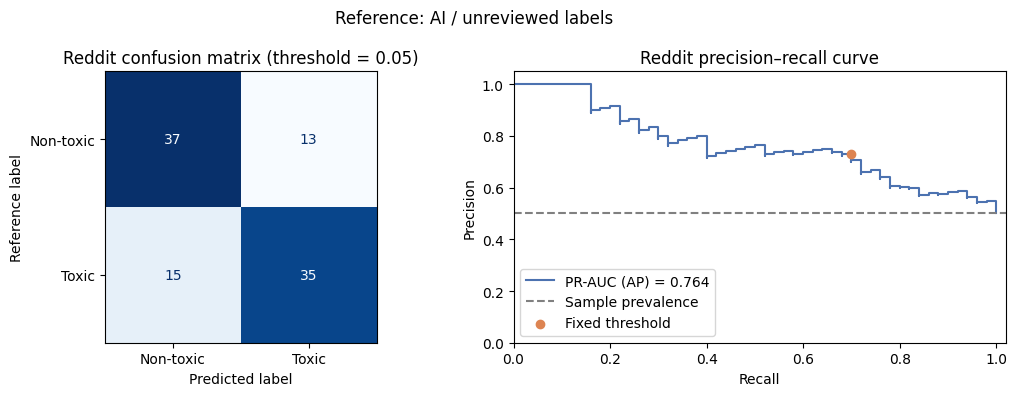

In [78]:
from sklearn.metrics import (average_precision_score, precision_score, recall_score,
                             f1_score, precision_recall_curve, ConfusionMatrixDisplay)

reddit_metrics = pd.DataFrame([{
    'n_comments': len(y_reddit),
    'threshold': reddit_threshold,
    'precision': precision_score(y_reddit, reddit_pred, zero_division=0),
    'recall': recall_score(y_reddit, reddit_pred, zero_division=0),
    'macro_f1': f1_score(y_reddit, reddit_pred, average='macro', zero_division=0),
    'pr_auc': average_precision_score(y_reddit, reddit_proba),
    'label_source': reddit_label_source,
}], index=['Reddit'])
display(reddit_metrics.round(4))

reddit_precision, reddit_recall, _ = precision_recall_curve(y_reddit, reddit_proba)
fig_reddit, axes_reddit = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_reddit, reddit_pred, labels=[0, 1], display_labels=['Non-toxic', 'Toxic'],
    cmap='Blues', colorbar=False, ax=axes_reddit[0],
)
axes_reddit[0].set_title(f'Reddit confusion matrix (threshold = {reddit_threshold:g})')
axes_reddit[0].set_ylabel('Reference label')
axes_reddit[1].step(reddit_recall, reddit_precision, where='post', color='#4C72B0',
                    label=f"PR-AUC (AP) = {reddit_metrics.loc['Reddit', 'pr_auc']:.3f}")
axes_reddit[1].axhline(y_reddit.mean(), color='grey', linestyle='--', label='Sample prevalence')
axes_reddit[1].scatter(reddit_metrics.loc['Reddit', 'recall'], reddit_metrics.loc['Reddit', 'precision'],
                       color='#DD8452', zorder=3, label='Fixed threshold')
axes_reddit[1].set(xlabel='Recall', ylabel='Precision', title='Reddit precision–recall curve',
                   xlim=(0, 1.02), ylim=(0, 1.05))
axes_reddit[1].legend(loc='lower left')
fig_reddit.suptitle(f'Reference: {reddit_label_source}')
fig_reddit.tight_layout()
plt.show()

### Inspect disagreements with the reference labels
`reddit_predictions` retains all 100 predictions with original text, cleaned input, label status and source links. `reddit_errors` contains only disagreements, with false positives/negatives defined relative to the supplied labels. For this AI-labelled sample, these may be annotation errors as well as model errors. Inspect the sources before drawing conclusions; keep this set out of model/threshold selection.

In [79]:
reddit_predictions = reddit_df.copy()
reddit_predictions['reference_label'] = y_reddit
reddit_predictions['predicted_label'] = reddit_pred
reddit_predictions['predicted_probability'] = reddit_proba
reddit_predictions['cleaned_text'] = reddit_cleaned
reddit_predictions['n_tokens'] = reddit_n_tokens
reddit_predictions['was_truncated'] = reddit_n_tokens > max_length
reddit_predictions['matches_reference'] = reddit_pred == y_reddit

reddit_errors = reddit_predictions.loc[~reddit_predictions['matches_reference']].copy()
reddit_errors['error_type'] = np.where(reddit_errors['reference_label'] == 1,
                                      'missed toxic (FN)', 'false alarm (FP)')
reddit_errors = reddit_errors.sort_values('predicted_probability')
print(f'Disagreements: {len(reddit_errors)}/{len(reddit_predictions)} against {reddit_label_source}')
print(reddit_errors['error_type'].value_counts().reindex(
    ['missed toxic (FN)', 'false alarm (FP)'], fill_value=0).to_string())
with pd.option_context('display.max_colwidth', 180):
    display(reddit_errors[['comment_id', 'reference_label', 'predicted_label',
                           'predicted_probability', 'error_type', 'n_tokens', 'was_truncated',
                           'text', 'cleaned_text', 'permalink']])

Disagreements: 28/100 against AI / unreviewed labels
error_type
missed toxic (FN)    15
false alarm (FP)     13


,comment_id,reference_label,predicted_label,predicted_probability,error_type,n_tokens,was_truncated,text,cleaned_text,permalink
6,ittx9ms,1,0,0.000682,missed toxic (FN),170,True,"Get a B2B knowledge-based job where what you ""sell"" is solutions to problems. Then you are half-way golden. A good tech support or Q&A job is basically being the goal-keeper; t...",get a b2b knowledge based job where what you sell is solutions to problems then you are half way golden a good tech support or q a job is basically being the goal keeper the le...,https://www.reddit.com/r/jobs/comments/ydiivm/to_all_the_people_with_remote_jobs/ittx9ms/
29,o3909ud,1,0,0.000683,missed toxic (FN),134,True,"This happens to me sometimes.\n\nIt's the ones where I think the call went really good - the person is saying ""oh that's great"" and ""good to hear"" and stuff like that, then the...",this happens to me sometimes it the ones where i think the call went really good the person is saying oh that great and good to hear and stuff like that then the next day get t...,https://www.reddit.com/r/jobs/comments/1qu94y7/rejected_minutes_after_a_phone_interview_and/o3909ud/
4,pbe2nmk,1,0,0.000768,missed toxic (FN),141,True,"I was hired at the same time another guy was, and we both were supposed to be doing the same thing at a senior level.\n\nFrom the get-go my interactions with him were negative ...",i was hired at the same time another guy was and we both were supposed to be doing the same thing at a senior level from the get go my interactions with him were negative somet...,https://www.reddit.com/r/jobs/comments/1wncq7j/just_got_my_first_remote_job/pbe2nmk/
75,pcmnfjo,1,0,0.002253,missed toxic (FN),26,False,"Yeah the manager is just an emotional dweeb. In a job of any importance, there actually are things to hand-off during that two week period.",yeah the manager is just an emotional dweeb in a job of any importance there actually are things to hand off during that two week period,https://www.reddit.com/r/jobs/comments/1wsezqo/comment/pcmnfjo/
61,judqjru,1,0,0.002431,missed toxic (FN),199,True,"I'd be homeless if it wasn't for family. So they think they can make random demeaning comments about how people just don't want to work these days. All I do is apply, study, an...",i would be homeless if it was not for family so they think they can make random demeaning comments about how people just do not want to work these days all i do is apply study ...,https://www.reddit.com/r/jobs/comments/15f3q6n/this_is_the_current_job_market_right_now/judqjru/
2,pcn06ve,1,0,0.002597,missed toxic (FN),117,True,"Fair pay, steady work, and a little appreciation. It's pretty simple. No MBA guru consultant necessary.\n\nIn the long run they save money because they're not spending money to...",fair pay steady work and a little appreciation it pretty simple no mba guru consultant necessary in the long run they save money because they are not spending money to train a ...,https://www.reddit.com/r/jobs/comments/1wsezqo/comment/pcn06ve/
54,m0t1g7n,1,0,0.003449,missed toxic (FN),114,True,The only sane post in the thread. All these morons are going “only contact HR if you don’t want to take legal action!”… what legal action? His boss sent a mean text after he qu...,the only sane post in the thread all these morons are going “only contact hr if you do not want to take legal action ! ” what legal action ? his boss sent a mean text after he ...,https://www.reddit.com/r/jobs/comments/1h83dku/im_what_on_sight/m0t1g7n/
97,jf27snz,1,0,0.003632,missed toxic (FN),549,True,"Long, but please read.\n\nUnless the company you're interviewing with is related to children or babies in any way, DO NOT MENTION IT.\n\nIf you're applying to work for Babies R...",long but please read unless the company you are interviewing with is related to children or babies in any way do not mention it if you are applying to work for babies r us then...,https://www.reddit.com/r/jobs/comments/12cmet3/should_i_tell_potential_emplo

## 15. Experiment summary and baseline comparison

Summarise the selected model, training and cross-validation metrics, and
held-out validation performance. Compare the Bi-LSTM with the package 3
baselines on the same pooled validation split.

Report the original 0.5 threshold and the OOF-selected threshold separately.
PR-AUC is computed as Average Precision (AP). Reddit results are reported
separately because they use a different dataset and may contain unreviewed
AI annotations.

This section reads existing results only; it does not train models or
select hyperparameters or thresholds. The baseline CSV must correspond
to the same pooled data version used by the Bi-LSTM.

In [80]:
from pathlib import Path
import numpy as np
import pandas as pd

metrics = ["precision", "recall", "macro_f1", "pr_auc"]

# 1. Search configuration
print("=== 1. Search configuration ===")
print("Number of trials:", search.n_iter)
print("Selected trial:", getattr(search, "best_trial", None))
print("Selected parameters:", search.best_params)
print("Training configuration:", search.kfold_kwargs)

# 2. Training and cross-validation performance
print("\n=== 2. Training and cross-validation performance ===")

cv_summary = pd.DataFrame({
    "Training mean": best_kf.avg_train_metrics,
    "CV mean": best_kf.avg_val_metrics,
    "CV standard deviation": best_kf.std_val_metrics,
}).T

display(cv_summary[metrics + ["loss"]].round(4))

# 3. Results for all search trials
print(f"\n=== 3. Cross-validation results: {len(search.results)} trials ===")

trial_columns = [
    column for column in search.results.columns
    if column.startswith("param_")
    or column in [
        "avg_val_pr_auc",
        "std_val_pr_auc",
        "avg_val_macro_f1",
        "selected",
    ]
]

display(search.results[trial_columns].round(4))

# 4. Load package 3 baseline metrics without manual upload
print("\n=== 4. Pooled validation: baseline comparison ===")

baseline_candidates = [
    Path("/dataset/pooled/baseline_metrics.csv"),
    Path("../dataset/pooled/baseline_metrics.csv"),
]

baseline_path = next(
    (path for path in baseline_candidates if path.is_file()),
    None,
)

baseline_rows = pd.DataFrame(columns=["model", "threshold"] + metrics)

if baseline_path is None:
    print("Baseline file not found. Checked:")
    for path in baseline_candidates:
        print(" -", path.resolve())
    print("Displaying Bi-LSTM results only.")
else:
    print("Baseline file:", baseline_path.resolve())
    baseline = pd.read_csv(baseline_path)

    required_columns = {"model", "group", *metrics}
    missing_columns = required_columns - set(baseline.columns)
    if missing_columns:
        raise ValueError(
            f"Missing baseline columns: {sorted(missing_columns)}"
        )

    baseline_rows = baseline.loc[
        baseline["group"] == "all"
    ].copy()

    if baseline_rows.empty:
        raise ValueError("The baseline CSV has no overall 'all' group.")

    # Do not guess thresholds if the CSV does not record them.
    if "threshold" not in baseline_rows.columns:
        baseline_rows["threshold"] = np.nan
        print("Baseline thresholds are not recorded in this CSV.")

    baseline_rows = baseline_rows[
        ["model", "threshold"] + metrics
    ]

# Explicitly evaluate the fixed reference threshold without changing
# best_kf.threshold or its OOF-selected operating point.
fixed_metrics = best_kf.evaluate_at(0.5)

lstm_rows = [{
    "model": "Bi-LSTM (fixed threshold)",
    "threshold": 0.5,
    **{metric: fixed_metrics[metric] for metric in metrics},
}]

tuned_threshold = getattr(best_kf, "tuned_threshold", None)
if tuned_threshold is not None:
    tuned_metrics = best_kf.evaluate_at(float(tuned_threshold))
    lstm_rows.append({
        "model": "Bi-LSTM (OOF-selected threshold)",
        "threshold": float(tuned_threshold),
        **{metric: tuned_metrics[metric] for metric in metrics},
    })

comparison = pd.concat(
    [baseline_rows, pd.DataFrame(lstm_rows)],
    ignore_index=True,
).set_index("model")

display(comparison.round(4))

print("PR-AUC uses Average Precision (AP).")
print("Compare only results produced from the same pooled validation split.")

# 5. Reddit evaluation is a separate dataset
print("\n=== 5. Reddit evaluation ===")

if "reddit_metrics" in globals():
    display(reddit_metrics.round(4))
    print(
        "If labels are AI-generated or unreviewed, these scores measure "
        "agreement with those annotations, not human-grounded accuracy."
    )
    print(
        "Ensure the Reddit evaluation was rerun after selecting the "
        "current model; an existing table may belong to an earlier run."
    )
else:
    print("Reddit evaluation has not been run.")

=== 1. Search configuration ===
Number of trials: 30
Selected trial: 26
Selected parameters: {'trainable': True, 'lstm_units': 9, 'dropout': 0.4996643288646504, 'lr': 0.0017707490585465965}
Training configuration: {'random_state': 42, 'n_splits': 5, 'epochs': 5, 'batch_size': 64, 'n_jobs': -1}

=== 2. Training and cross-validation performance ===


,precision,recall,macro_f1,pr_auc,loss
Training mean,0.9246,0.8451,0.9314,0.9540,0.0922
CV mean,0.8094,0.6790,0.8477,0.8194,0.2255
CV standard deviation,0.0329,0.0301,0.0130,0.0180,0.0211



=== 3. Cross-validation results: 30 trials ===


,param_trainable,param_lstm_units,param_dropout,param_lr,avg_val_macro_f1,avg_val_pr_auc,std_val_pr_auc,selected
trial,,,,,,,,
1,False,13,0.3898,0.0024,0.8153,0.7819,0.0203,False
2,True,11,0.2296,0.0010,0.8429,0.8134,0.0233,False
3,True,49,0.0282,0.0038,0.8120,0.7640,0.0239,False
4,False,8,0.4961,0.0026,0.8100,0.7711,0.0193,False
5,False,8,0.0115,0.0019,0.8172,0.7780,0.0271,False
6,True,9,0.4869,0.0007,0.8358,0.8007,0.0179,False
7,True,44,0.1912,0.0094,0.8163,0.7732,0.0233,False
8,True,87,0.3402,0.0015,0.8440,0.8167,0.0239,False
9,True,109,0.2816,0.0012,0.8470,0.8207,0.0230,False



=== 4. Pooled validation: baseline comparison ===
Baseline file: /content/IS5126_grp6_final_project/dataset/pooled/baseline_metrics.csv


,threshold,precision,recall,macro_f1,pr_auc
model,,,,,
majority,0.50,0.0000,0.0000,0.4589,0.1520
tfidf_logreg,0.50,0.9338,0.3868,0.7463,0.7678
tfidf_logreg_balanced,0.50,0.6847,0.6941,0.8166,0.7670
Bi-LSTM (fixed threshold),0.50,0.8136,0.6584,0.8422,0.8081
Bi-LSTM (OOF-selected threshold),0.05,0.4996,0.8340,0.7647,0.8081


PR-AUC uses Average Precision (AP).
Compare only results produced from the same pooled validation split.

=== 5. Reddit evaluation ===


,n_comments,threshold,precision,recall,macro_f1,pr_auc,label_source
Reddit,100,0.05,0.7292,0.7,0.7199,0.7641,AI / unreviewed labels


If labels are AI-generated or unreviewed, these scores measure agreement with those annotations, not human-grounded accuracy.
Ensure the Reddit evaluation was rerun after selecting the current model; an existing table may belong to an earlier run.
